# 定义损失函数：传入参数向量（二元）

In [12]:
import torch
from torch.optim import SGD, Adam, AdamW
import numpy as np
import matplotlib.pyplot as plt

# 定义损失函数：传入参数向量（二元）
def f(w):
    return 0.05 * w[0]**2 + w[1] ** 2

In [13]:
# 定义函数，实现梯度下降法流程，传入 初始参数、优化器、训练迭代次数
def gradient_descent(w, optimizer, n_iters):
    # 用列表保存参数点坐标
    w0_list = []
    w1_list = []
    for i in range(n_iters):
        w0_list.append(w[0].item())
        w1_list.append(w[1].item())
        # 1. 前向传播、计算损失
        loss = f(w)
        # 2. 反向传播
        loss.backward()
        # 3. 更新参数
        optimizer.step()
        # 4. 梯度清零
        optimizer.zero_grad()
    return w0_list, w1_list

In [14]:
# 定义训练超参数
lr = 0.1
n_iters = 500

# 定义初始参数
start_w=[-7.0,2]

# 对比不同的优化器
## 1. SGD

In [15]:
sgd_w = torch.tensor(start_w, requires_grad=True)
optimizer = SGD([sgd_w], lr=lr)
sgd_w0_list, sgd_w1_list = gradient_descent(sgd_w, optimizer, n_iters)

# 2. Adam

In [16]:

# 重新初始化
adam_w = torch.tensor(start_w, requires_grad=True)
optimizer = Adam([adam_w], lr=lr)
adam_w0_list, adam_w1_list = gradient_descent(adam_w, optimizer, n_iters)


# 对比图

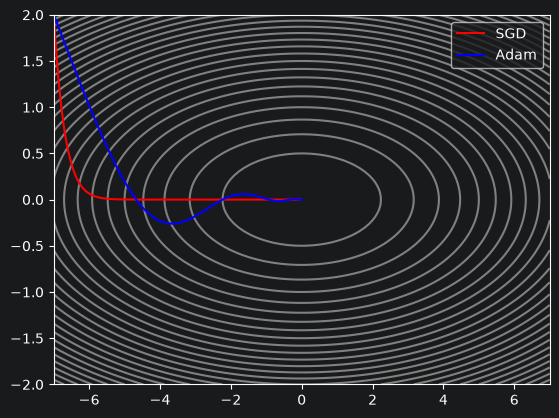

In [17]:
w0, w1 = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
loss = f([w0, w1])
plt.contour(w0, w1, loss, colors='gray', levels=30)
plt.plot(sgd_w0_list, sgd_w1_list, color='r')
plt.plot(adam_w0_list, adam_w1_list, color='b')
plt.legend(['SGD', 'Adam'])
plt.show()

# 总结
结合了动量法和 RMSprop 的优点，同时考虑梯度的一阶矩和二阶矩，是目前最常用、表现最稳定的优化器之一。

解决了四个问题：
- 震荡幅度变小，因为考虑了历史梯度，当梯度震荡时，正负抵消
- 引入 “惯性” 概念，利用历史梯度平滑当前更新方向，加速收敛。
- 因为v h 都不可能为0，所以不会卡在鞍点
- 动态自适应学习率 开始迭代学习率较大 越往 后越小

参考 总结 优化器的本质：重构你的认知框架

# 总结
结合了动量法和 RMSprop 的优点，同时考虑梯度的一阶矩和二阶矩，是目前最常用、表现最稳定的优化器之一。